In [1]:
from google.colab import drive
drive.mount('/content/drive')

# Your images should be organized like:
# /content/drive/MyDrive/agroguard_data/growth_stage/Week1/*.jpg
# /content/drive/MyDrive/agroguard_data/growth_stage/Week2/*.jpg  ... etc

DATA_DIR = "/content/drive/MyDrive/growth_stage"

Mounted at /content/drive


In [2]:
import os

# List contents of DATA_DIR
print(f"Listing contents of {DATA_DIR}:")
!ls -F "{DATA_DIR}"

Listing contents of /content/drive/MyDrive/growth_stage:
week1/	week2/	week3/	week4/	week5/	week6/	week7/	week8/	week9/


Loading image: /content/drive/MyDrive/growth_stage/week1/crop_corn_w1_0_006614.jpg


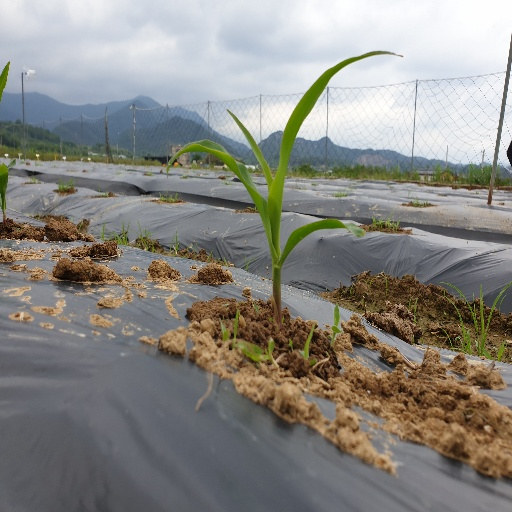

In [3]:
from PIL import Image
import glob
import os

# Construct the path to the week1 folder
week1_path = os.path.join(DATA_DIR, 'week1')

# Get a list of all image files in week1
image_files = glob.glob(os.path.join(week1_path, '*.jpg')) # Assuming .jpg, adjust if needed

if image_files:
    # Load the first image found
    sample_image_path = image_files[0]
    print(f"Loading image: {sample_image_path}")
    img = Image.open(sample_image_path)

    # Display the image (Colab will render PIL images directly)
    display(img)
else:
    print(f"No image files found in {week1_path}. Please check the directory and file extensions.")

In [4]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

CUDA available: True
Device: Tesla T4


In [5]:
!pip install -q mlflow  # only extra thing you likely need
import torch, torchvision
print(torch.__version__, torchvision.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 4.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 kB 4.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 131.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 123.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 96.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 28.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 212.0/212.0 kB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.9/123.9 kB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132.2/132.2 kB 14.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [6]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# Ensure DATA_DIR is defined for this cell's execution, in case previous cells were not run.
# DATA_DIR is originally defined in cell 'q-r89bn5hM-o'.
DATA_DIR = "/content/drive/MyDrive/growth_stage"

IMG_SIZE = 224
BATCH_SIZE = 32

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

full_dataset = datasets.ImageFolder(DATA_DIR, transform=train_transforms)
class_names = full_dataset.classes
print("Classes found:", class_names)

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_ds, val_ds = random_split(full_dataset, [train_size, val_size])
val_ds.dataset.transform = val_transforms

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

Classes found: ['week1', 'week2', 'week3', 'week4', 'week5', 'week6', 'week7', 'week8', 'week9']


In [7]:
import torch.nn as nn
from torchvision import models

NUM_CLASSES = len(class_names)  # 11 for growth stage, or your disease count for CWD20

model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
model.classifier[1] = nn.Linear(model.last_channel, NUM_CLASSES)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 128MB/s]


In [8]:
import mlflow

EPOCHS = 30
mlflow.set_experiment("agroguard-growth-stage")

with mlflow.start_run():
    mlflow.log_params({"epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": 1e-4, "model": "mobilenet_v2"})

    for epoch in range(EPOCHS):
        model.train()
        train_loss, correct, total = 0, 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        train_acc = correct / total
        train_loss = train_loss / total

        # validation
        model.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = model(imgs)
                _, preds = torch.max(outputs, 1)
                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)
        val_acc = val_correct / val_total

        print(f"Epoch {epoch+1}/{EPOCHS} | train_loss={train_loss:.4f} train_acc={train_acc:.4f} val_acc={val_acc:.4f}")
        mlflow.log_metrics({"train_loss": train_loss, "train_acc": train_acc, "val_acc": val_acc}, step=epoch)

    mlflow.pytorch.log_model(model, "model")

2026/08/10 10:07:51 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/08/10 10:07:51 INFO mlflow.store.db.utils: Updating database tables
2026/08/10 10:07:54 INFO mlflow.tracking.fluent: Experiment with name 'agroguard-growth-stage' does not exist. Creating a new experiment.


Epoch 1/30 | train_loss=1.1453 train_acc=0.6652 val_acc=0.8370
Epoch 2/30 | train_loss=0.3694 train_acc=0.8836 val_acc=0.9120
Epoch 3/30 | train_loss=0.1788 train_acc=0.9493 val_acc=0.9454
Epoch 4/30 | train_loss=0.1018 train_acc=0.9735 val_acc=0.9454
Epoch 5/30 | train_loss=0.0543 train_acc=0.9880 val_acc=0.9495
Epoch 6/30 | train_loss=0.0389 train_acc=0.9902 val_acc=0.9625
Epoch 7/30 | train_loss=0.0246 train_acc=0.9955 val_acc=0.9609
Epoch 8/30 | train_loss=0.0245 train_acc=0.9941 val_acc=0.9487
Epoch 9/30 | train_loss=0.0149 train_acc=0.9976 val_acc=0.9641
Epoch 10/30 | train_loss=0.0209 train_acc=0.9951 val_acc=0.9511
Epoch 11/30 | train_loss=0.0189 train_acc=0.9953 val_acc=0.9576
Epoch 12/30 | train_loss=0.0141 train_acc=0.9974 val_acc=0.9617
Epoch 13/30 | train_loss=0.0074 train_acc=0.9986 val_acc=0.9674
Epoch 14/30 | train_loss=0.0093 train_acc=0.9982 val_acc=0.9641
Epoch 15/30 | train_loss=0.0121 train_acc=0.9967 val_acc=0.9593
Epoch 16/30 | train_loss=0.0090 train_acc=0.9980 

2026/08/10 11:12:53 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Epoch 30/30 | train_loss=0.0055 train_acc=0.9992 val_acc=0.9690


MlflowException: If `serialization_format` is set to 'pt2', then input_example is required. It must be a numpy array or torch tensor, or a tuple/list of numpy arrays or torch tensors. This is because 'pt2' is a traced-graph format: PyTorch traces the model graph by virtually executing model.forward with the provided example input.

In [9]:
torch.save(model.state_dict(), "/content/growth_stage_model.pt")

from google.colab import files
files.download("/content/growth_stage_model.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import torch
from torchvision import models
import torch.nn as nn

model = models.mobilenet_v2(weights=None)
model.classifier[1] = nn.Linear(model.last_channel, NUM_CLASSES)
model.load_state_dict(torch.load("growth_stage_model.pt", map_location="cpu"))
model.eval()

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=

In [11]:
!pip install -q opencv-contrib-python
import cv2
import numpy as np
print("OpenCV version:", cv2.__version__)
print("ArUco available:", hasattr(cv2, "aruco"))


OpenCV version: 4.13.0
ArUco available: True


In [13]:
# Placeholder healthy height ranges (cm) per week — REPLACE with real reference data
EXPECTED_HEIGHT_RANGES = {
    "Week1": (2, 5),
    "Week2": (5, 9),
    "Week3": (9, 14),
    "Week4": (14, 20),
    "Week5": (20, 27),
    "Week6": (27, 35),
    "Week7": (35, 44),
    "Week8": (44, 54),
    "Week9": (54, 65),
}

In [14]:
def measure_height_cm(image_path, marker_real_size_cm=8.5, marker_dict=cv2.aruco.DICT_4X4_50):
    """
    Detects an ArUco marker in the image and uses it to convert the plant's
    pixel height into real-world centimeters.

    Returns:
        (height_cm: float or None, status: "Detected" or "No_Marker")
    """
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Could not read image: {image_path}")

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    aruco_dict = cv2.aruco.getPredefinedDictionary(marker_dict)
    detector = cv2.aruco.ArucoDetector(aruco_dict, cv2.aruco.DetectorParameters())
    corners, ids, _ = detector.detectMarkers(gray)

    if ids is None or len(corners) == 0:
        return None, "No_Marker"

    # Use the first detected marker as the reference
    marker_corners = corners[0][0]
    marker_pixel_height = marker_corners[:, 1].max() - marker_corners[:, 1].min()
    if marker_pixel_height <= 0:
        return None, "No_Marker"

    pixels_per_cm = marker_pixel_height / marker_real_size_cm

    # --- Plant top/base detection ---
    # Simple green-mask segmentation (demo-grade). For production accuracy,
    # replace this block with a trained segmentation model.
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    lower_green = np.array([25, 40, 40])
    upper_green = np.array([95, 255, 255])
    plant_mask = cv2.inRange(hsv, lower_green, upper_green)

    ys, xs = np.where(plant_mask > 0)
    if len(ys) == 0:
        return None, "No_Marker"  # no plant pixels found either

    plant_top_px = ys.min()
    plant_base_px = ys.max()
    plant_height_px = plant_base_px - plant_top_px

    height_cm = plant_height_px / pixels_per_cm
    return round(float(height_cm), 1), "Detected"

In [15]:
def evaluate_height_status(detected_stage, height_cm):
    """
    Compares measured height to the expected range for the detected growth week.
    Returns (height_status, expected_range_str, recommended_modules: list)
    """
    if height_cm is None:
        return "No_Marker", "N/A", []

    if detected_stage not in EXPECTED_HEIGHT_RANGES:
        return "Unknown_Stage", "N/A", []

    low, high = EXPECTED_HEIGHT_RANGES[detected_stage]
    expected_range_str = f"{low}-{high} cm"

    if height_cm < low:
        return "Stunted", expected_range_str, ["Fertilizer & Pesticide", "Smart Irrigation"]
    elif height_cm > high:
        return "Overgrown", expected_range_str, ["Smart Irrigation"]
    else:
        return "Healthy", expected_range_str, []

In [16]:
def generate_scan_report(detected_stage, confidence_score, height_cm, height_status,
                          expected_range_str, crop_match, recommended_modules,
                          detected_disease=None, disease_confidence=None):
    """
    Builds a clean bullet-point scan summary report as plain text,
    matching the growth_stage_log.scan_summary field in the SRS.
    """
    lines = []
    lines.append(f"- Growth stage detected: {detected_stage} (confidence: {confidence_score:.0%})")

    if height_cm is not None:
        lines.append(f"- Measured height: {height_cm} cm (expected: {expected_range_str})")
        lines.append(f"- Height status: {height_status}")
    else:
        lines.append("- Height status: Could not be measured (no reference marker detected in image)")

    lines.append(f"- Crop match: {'Yes' if crop_match else 'No — image may not match the selected crop type'}")

    if detected_disease:
        lines.append(f"- Disease detected: {detected_disease} (confidence: {disease_confidence:.0%})")
    else:
        lines.append("- Disease detected: None")

    if recommended_modules:
        modules_str = ", ".join(recommended_modules)
        lines.append(f"- Recommended next step: check {modules_str}")
    else:
        lines.append("- Recommended next step: none — plant is on track")

    return "\n".join(lines)

In [17]:
from torchvision import transforms
from PIL import Image
import torch.nn.functional as F

inference_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

def analyze_scan(image_path, declared_crop_type=None, crop_match=True,
                  marker_real_size_cm=8.5):
    """
    Full Module 2 pipeline for a single image:
    growth-stage prediction + height measurement + health check + report.
    (Disease detection plugs in separately once that model is trained.)
    """
    # 1. Growth stage prediction
    img = Image.open(image_path).convert("RGB")
    input_tensor = inference_transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(input_tensor)
        probs = F.softmax(outputs, dim=1)
        confidence, predicted_idx = torch.max(probs, 1)

    detected_stage = class_names[predicted_idx.item()]
    confidence_score = confidence.item()

    # 2. Height measurement
    height_cm, marker_status = measure_height_cm(image_path, marker_real_size_cm)

    # 3. Health status check
    height_status, expected_range_str, recommended_modules = evaluate_height_status(
        detected_stage, height_cm
    )

    # 4. Report
    report = generate_scan_report(
        detected_stage, confidence_score, height_cm, height_status,
        expected_range_str, crop_match, recommended_modules
    )

    return {
        "detected_stage": detected_stage,
        "confidence_score": round(confidence_score, 4),
        "measured_height_cm": height_cm,
        "expected_height_range": expected_range_str,
        "height_status": height_status,
        "crop_match": crop_match,
        "recommended_modules": recommended_modules,
        "scan_summary": report,
    }

In [ ]:
import torch
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# 1. Ensure model is in eval mode and predict validation set
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:  # replace with your validation loader variable
        images = images.to(device)
        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 2. Generate confusion matrix & class metrics
cm = confusion_matrix(all_labels, all_preds)
report = classification_report(all_labels, all_preds)

print("--- Confusion Matrix (Copy this array) ---")
print(cm.tolist())
print("\n--- Classification Report ---")
print(report)